In [74]:
import cv2
import mediapipe as mp
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
import numpy as np

In [75]:
# Configure MediaPipe
BaseOptions = mp.tasks.BaseOptions
FaceLandmarker = mp.tasks.vision.FaceLandmarker
FaceLandmarkerOptions = mp.tasks.vision.FaceLandmarkerOptions
VisionRunningMode = mp.tasks.vision.RunningMode

options = FaceLandmarkerOptions(
    base_options=BaseOptions(model_asset_path="face_landmarker.task"),
    running_mode=VisionRunningMode.VIDEO,
    num_faces=1,
    output_face_blendshapes=True
)

# Open video
video_path = "data/test_video.mov"
cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

print(f"FPS: {fps}, Frames: {total_frames}")


FPS: 29.998430778235036, Frames: 35366


In [76]:
results_list = []
n = 10000
step = 3

error_n = 0
# Process video
with FaceLandmarker.create_from_options(options) as landmarker:
    frame_idx = 0
    while cap.isOpened() and frame_idx < n*step:
        ret, frame = cap.read()
    
        if not ret:
            break

        timestamp_ms = int(frame_idx / fps * 1000)

        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=frame_rgb
        )

        result = landmarker.detect_for_video(
            mp_image,
            timestamp_ms
        )

        if result.face_landmarks:
            h, w, _ = frame.shape

            for landmark in result.face_landmarks[0]:
                x = int(landmark.x * w)
                y = int(landmark.y * h)

                cv2.circle(
                    frame,
                    (x, y),
                    radius=1,
                    color=(0, 255, 0),
                    thickness=-1
                )

        if result.face_blendshapes:
            blendshapes = result.face_blendshapes[0]
        
            blendshape_features = {
                category.category_name: category.score
                for category in blendshapes
            }
            blendshape_features['frame_idx'] = frame_idx
            results_list.append(blendshape_features)
        else:
            print("No face found")
            error_n += 1

        if False:
            plt.clf()
            plt.figure(figsize=(10, 6))
            plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
            plt.title(f"Frame: {frame_idx}")
            plt.axis("off")
            display(plt.gcf())
            clear_output(wait=True)
            
        print(frame_idx)
        frame_idx += step

cap.release()

df = pd.DataFrame(results_list)

print(f'Found object in {len(df)} of {n} samples')

No face found
0
No face found
3
No face found
6
No face found
9
No face found
12
No face found
15
No face found
18
No face found
21
No face found
24
No face found
27
No face found
30
No face found
33
No face found
36
No face found
39
No face found
42
No face found
45
No face found
48
51
54
57
60
63
66
69
72
75
78
81
84
87
90
93
96
99
102
105
108
111
114
117
120
123
126
129
132
135
138
141
144
147
150
153
156
159
162
165
168
171
174
177
180
183
186
189
192
195
198
201
204
207
210
213
216
219
222
225
228
231
234
237
240
243
246
249
252
255
258
261
264
267
270
273
276
279
282
285
288
291
294
297
300
303
306
309
312
315
318
321
324
327
330
333
336
339
342
345
348
351
354
357
360
363
366
369
372
375
378
381
384
387
390
393
396
399
402
405
408
411
414
417
420
423
426
429
432
435
438
441
444
447
450
453
456
459
462
465
468
471
474
477
480
483
486
489
492
495
498
501
504
507
510
513
516
519
522
525
528
531
534
537
540
543
546
549
552
555
558
561
564
567
570
573
576
579
582
585
588
591
594
597


In [77]:
display(df)

,_neutral,browDownLeft,browDownRight,browInnerUp,browOuterUpLeft,browOuterUpRight,cheekPuff,cheekSquintLeft,cheekSquintRight,eyeBlinkLeft,...,mouthShrugUpper,mouthSmileLeft,mouthSmileRight,mouthStretchLeft,mouthStretchRight,mouthUpperUpLeft,mouthUpperUpRight,noseSneerLeft,noseSneerRight,frame_idx
0,1.124604e-06,0.000156,0.000080,0.717735,0.584941,0.649571,0.000055,3.871457e-07,7.488090e-07,0.098459,...,0.000730,0.002423,0.002477,0.002837,0.001524,0.000004,8.675261e-06,3.731155e-07,4.131274e-07,51
1,8.747945e-07,0.000223,0.000093,0.706223,0.576996,0.643857,0.000054,2.572349e-07,3.676712e-07,0.124359,...,0.000551,0.012703,0.019903,0.002441,0.003246,0.000008,1.660391e-05,3.397671e-07,3.242463e-07,54
2,9.485096e-07,0.000265,0.000131,0.681238,0.528828,0.550949,0.000049,3.540584e-07,2.933739e-07,0.132166,...,0.000871,0.015335,0.028482,0.002607,0.003819,0.000014,2.832596e-05,3.791894e-07,3.094208e-07,57
3,8.483369e-07,0.000282,0.000145,0.657277,0.535084,0.576091,0.000048,2.778210e-07,3.007888e-07,0.127006,...,0.000695,0.010028,0.015109,0.001990,0.002131,0.000009,1.530036e-05,3.594612e-07,2.803933e-07,60
4,8.651935e-07,0.000249,0.000138,0.685093,0.555742,0.580996,0.000046,2.746830e-07,2.843865e-07,0.117108,...,0.000591,0.007028,0.010736,0.001327,0.001660,0.000006,1.070711e-05,2.908498e-07,2.593810e-07,63
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9217,4.323764e-07,0.000116,0.000047,0.754359,0.753282,0.830566,0.000089,1.833661e-07,6.401813e-07,0.227834,...,0.000180,0.000979,0.000227,0.000200,0.000147,0.000006,7.844921e-07,1.291407e-06,1.944479e-07,29985
9218,4.367182e-07,0.000089,0.000033,0.805312,0.799297,0.858696,0.000087,2.097277e-07,6.506120e-07,0.248582,...,0.000189,0.001023,0.000219,0.000228,0.000147,0.000005,7.354506e-07,1.261593e-06,2.027575e-07,29988
9219,4.881721e-07,0.000081,0.000032,0.832451,0.803282,0.850841,0.000087,2.444519e-07,6.286984e-07,0.257803,...,0.000217,0.001242,0.000249,0.000263,0.000144,0.000005,6.922704e-07,1.175016e-06,2.142226e-07,29991
9220,5.807035e-07,0.000108,0.000039,0.825675,0.758380,0.830347,0.000079,2.864380e-07,5.991319e-07,0.272686,...,0.000244,0.001191,0.000231,0.000311,0.000146,0.000003,4.846452e-07,1.079614e-06,2.257775e-07,29994


In [78]:
# df.to_csv("video_features.csv", index=False)

In [79]:
if frame_idx % 5 != 0:
    frame_idx += 1

In [80]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

X_raw = df.drop(columns=['frame_idx'])

X_scaled = StandardScaler().fit_transform(X_raw)

pca = PCA(n_components=11)
X_pca = pca.fit_transform(X_scaled)

n_clusters = 5

In [81]:
import torch
import torch.nn as nn
import torch.optim as optim

# 1. Definiera Autoencodern
class BlendshapeAutoencoder(nn.Module):
    def __init__(self, input_dim=52, latent_dim=10):
        super().__init__()
        # Encoder: Komprimerar 52 -> 32 -> latent_dim (t.ex. 10)
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Linear(32, latent_dim)
        )
        # Decoder: Rekonstruerar tillbaka från latent_dim -> 32 -> 51
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, input_dim)
        )
        
    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

# 2. Konvertera din skalade data till PyTorch-tensors
X_tensor = torch.FloatTensor(X_scaled)

# 3. Initiera modell, förlustfunktion och optimerare
input_dim = X_scaled.shape[1]
latent_dim = 5 # Motsvarar n_components=10 som du hade i PCA
model = BlendshapeAutoencoder(input_dim=input_dim, latent_dim=latent_dim)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 4. Träna autoencodern (enkelt träningssteg)
epochs = 100
model.train()
for epoch in range(epochs):
    optimizer.zero_grad()
    reconstructions = model(X_tensor)
    loss = criterion(reconstructions, X_tensor)
    loss.backward()
    optimizer.step()

# 5. Extrahera det latenta rummet (ersätter X_pca)
model.eval()
with torch.no_grad():
    X_ae = model.encoder(X_tensor).numpy()

In [82]:
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
labels_AE = kmeans.fit_predict(X_ae)
labels_PCA = kmeans.fit_predict(X_pca)

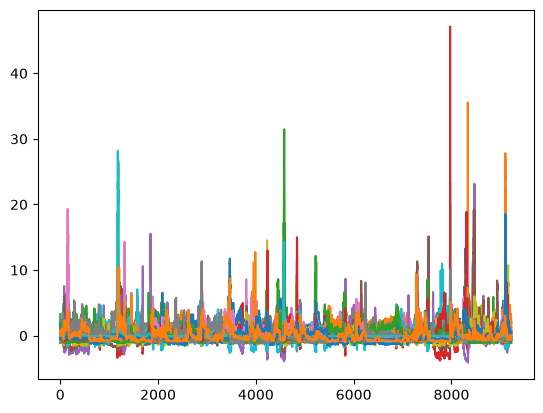

In [83]:
plt.plot(X_scaled)
plt.show()

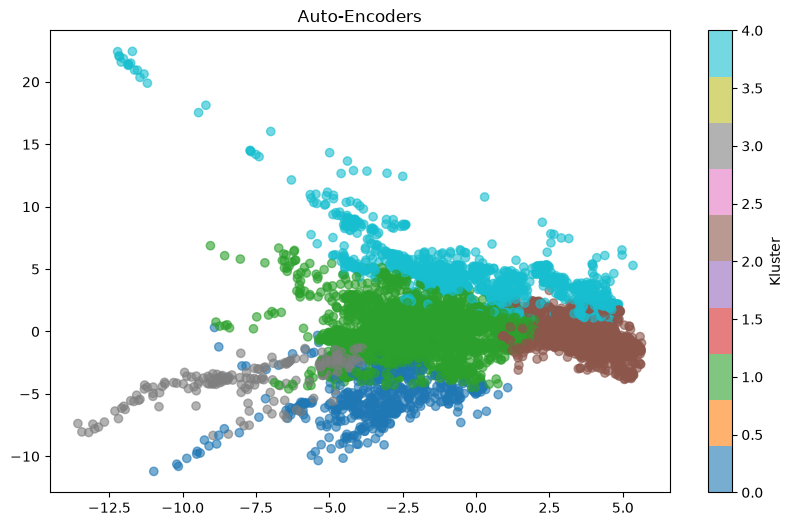

In [84]:
plt.figure(figsize=(10, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_AE, cmap='tab10', alpha=0.6)
plt.title("Auto-Encoders")
plt.colorbar(label='Kluster')
plt.show()

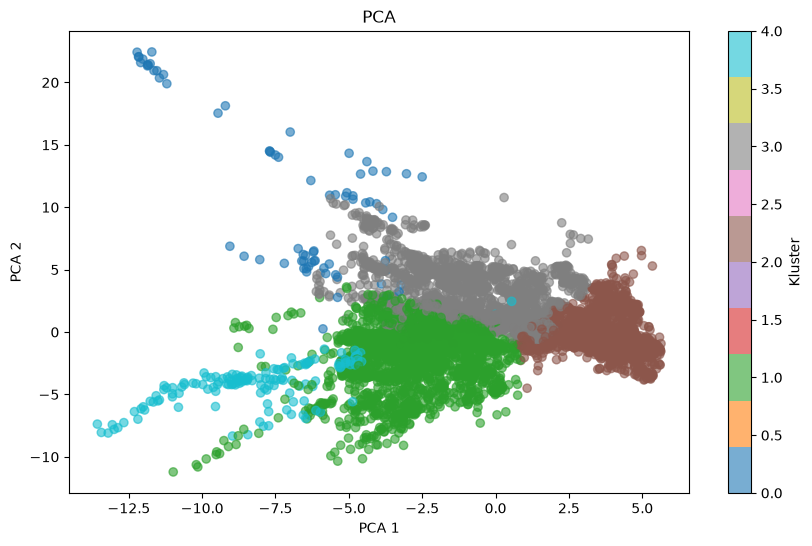

In [85]:
plt.figure(figsize=(10, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_PCA, cmap='tab10', alpha=0.6)
plt.title("PCA")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.colorbar(label='Kluster')
plt.show()

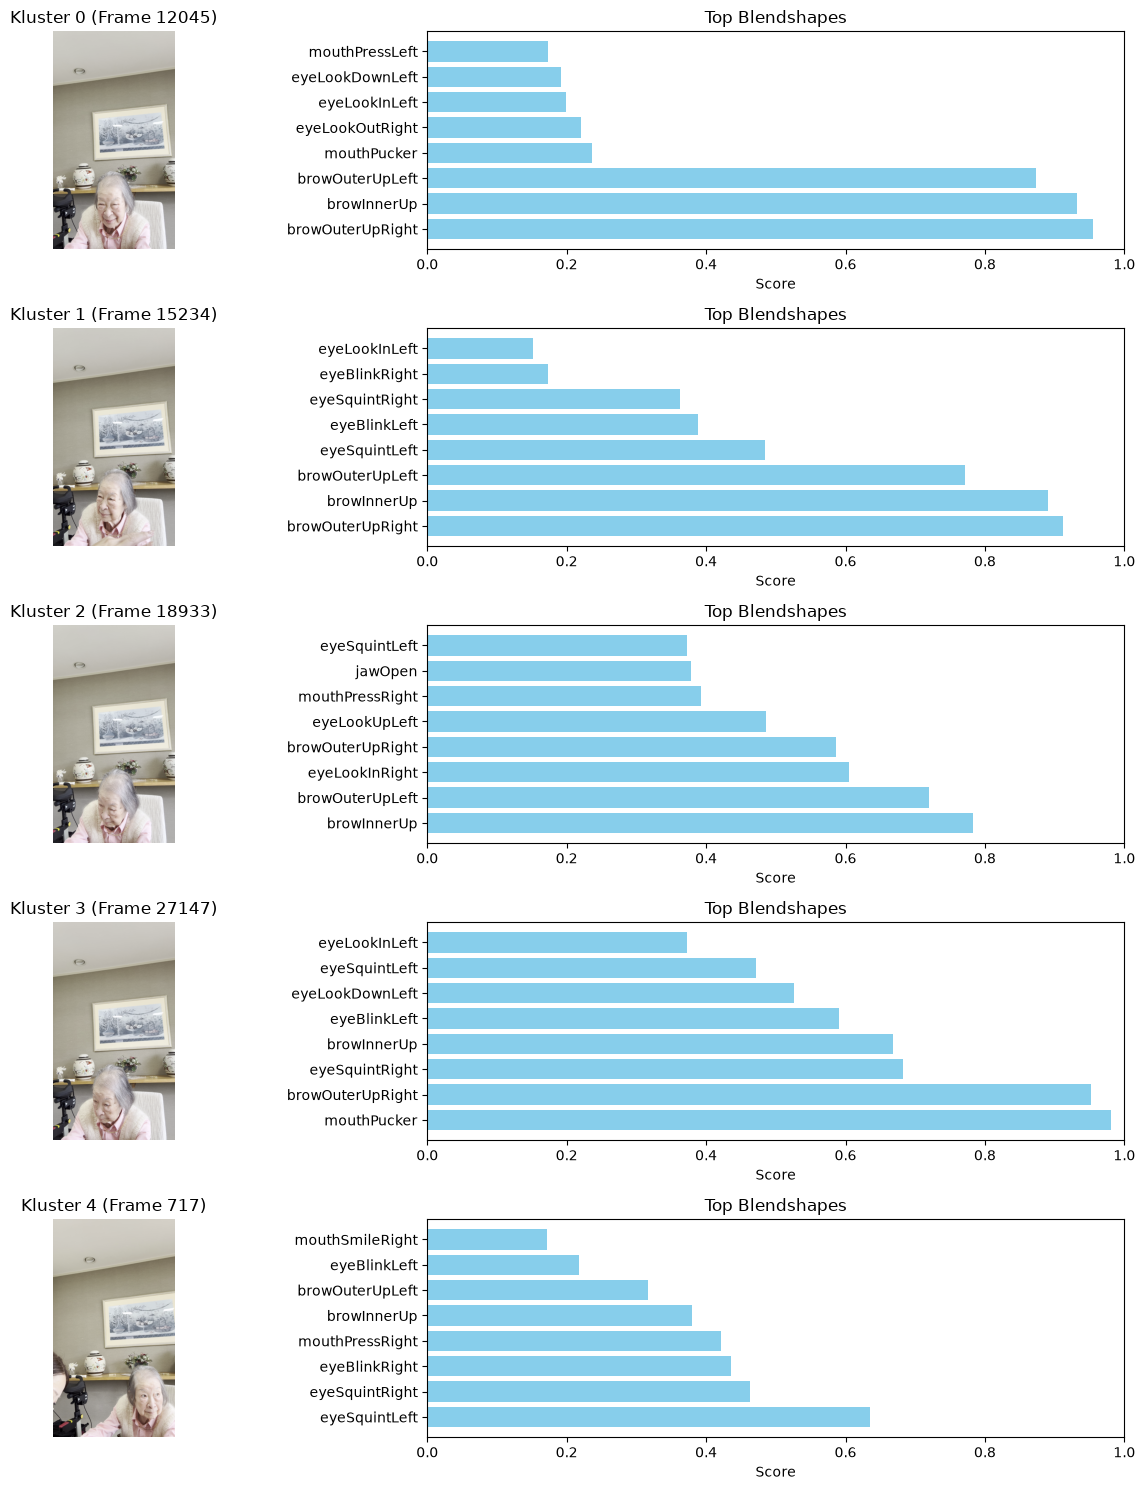

In [86]:
# Antal kluster du har (samma som n_clusters i din KMeans)
n_clusters = len(np.unique(labels_AE))

# Hitta ursprungliga kolumnnamn för blendshapes (alla kolumner förutom 'frame_idx')
blendshape_cols = [col for col in df.columns if col != 'frame_idx']

plt.figure(figsize=(14, 3 * n_clusters))

for cluster_id in range(n_clusters):
    # Hitta alla index i vår DataFrame som tillhör detta kluster
    cluster_mask = (labels_AE == cluster_id)
    cluster_indices = np.where(cluster_mask)[0]
    
    if len(cluster_indices) == 0:
        continue
        
    # Hitta punkten som ligger närmast klustrets centroid i PCA-rymden
    cluster_pca = X_pca[cluster_mask]
    cluster_centroid = np.mean(cluster_pca, axis=0)
    distances = np.linalg.norm(cluster_pca - cluster_centroid, axis=1)
    best_idx_in_cluster = cluster_indices[np.argmin(distances)]
    
    # Hämta motsvarande bildrutans index och läs in bilden från videon
    target_frame_idx = int(df.iloc[best_idx_in_cluster]['frame_idx'])
    
    cap = cv2.VideoCapture(video_path)
    cap.set(cv2.CAP_PROP_POS_FRAMES, target_frame_idx)
    ret, frame = cap.read()
    cap.release()
    
    if not ret:
        continue
        
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    
    # Hämta de högsta blendshapes för detta kluster (medelvärde eller den bästa bilden)
    bs_values = df.iloc[best_idx_in_cluster][blendshape_cols].astype(float)
    top_features = bs_values.nlargest(8)  # Visa de 8 starkaste muskelrörelserna

    # --- Rita subplots: Bild till vänster, Stapeldiagram till höger ---
    
    # 1. Bilden
    plt.subplot(n_clusters, 2, cluster_id * 2 + 1)
    plt.imshow(frame_rgb)
    plt.title(f"Kluster {cluster_id} (Frame {target_frame_idx})")
    plt.axis('off')
    
    # 2. Stapeldiagrammet (Bars)
    plt.subplot(n_clusters, 2, cluster_id * 2 + 2)
    y_pos = np.arange(len(top_features))
    plt.barh(y_pos, top_features.values, align='center', color='skyblue')
    plt.yticks(y_pos, top_features.index)
    plt.xlabel("Score")
    plt.title("Top Blendshapes")
    plt.xlim(0, 1.0)

plt.tight_layout()
plt.show()

In [87]:
# Skapa en temporär DataFrame för visualisering av det latenta rummet
df_latent = pd.DataFrame(X_ae[:, :2], columns=['Latent 1', 'Latent 2'])
df_latent['Cluster'] = labels_AE.astype(
    str
)  # Konvertera till sträng för diskreta färger
df_latent['frame_idx'] = df[
    'frame_idx'
].values  # Valfritt om du vill ha med frame_idx

fig = px.scatter(
    df_latent,
    x='Latent 1',
    y='Latent 2',
    color='Cluster',
    hover_data=['frame_idx'],
    title='Autoencoder Latent Space - K-Means Kluster',
)
fig.show()